# Dataset- Crime Data from 2020 to 2024
Team members:
Hrishikesh Samant
Sukrut Patil
Neer Shah
Krishna Parekh

Dataset link - https://catalog.data.gov/dataset/crime-incidents-in-the-last-30-days



# Phase 1:Dataset Understanding & Data Preprocessing

In [ ]:
from google.colab import files
uploaded = files.upload()

In [20]:


#0.Import dataset:
import pandas as pd
df = pd.read_csv("dataset.csv")
df.head()

#1.Attribute Identification:
for col in df.columns:
   print("Attribute:", col)
   print("Data Type:", df[col].dtype)
   print("Unique Values:", df[col].nunique())
   print("Sample Values:", df[col].dropna().unique()[:10])

#2.Data Quality Assessment:
missing = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage':
        (df.isnull().sum() / len(df) * 100).round(2)
})

missing = missing[missing['Missing Count'] > 0].sort_values(
    'Missing Count',
    ascending=False
)

display(missing)


#3.Missing Data Handling: (mode imputation)
empty_columns = df.columns[df.isnull().all()]

df = df.drop(columns=empty_columns)
if "BID" in df.columns:
    df["BID"] = df["BID"].fillna("Unknown")

mode_columns = [
    "ANC",
    "NEIGHBORHOOD_CLUSTER",
    "BLOCK_GROUP",
    "VOTING_PRECINCT",
    "WARD",
    "CENSUS_TRACT"
]

for col in mode_columns:
    if col in df.columns:
        df[col] = df[col].fillna(df[col].mode()[0])

date_columns = ["START_DATE", "END_DATE"]

for col in date_columns:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

if "START_DATE" in df.columns:

    valid_dates = df["START_DATE"].dropna().sort_values()

    if df["START_DATE"].isnull().sum() > 0:
        median_start_date = valid_dates.iloc[len(valid_dates) // 2]
        df["START_DATE"] = df["START_DATE"].fillna(
            median_start_date
        )
final_missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().sum() / len(df)) * 100
})

final_missing = final_missing[
    final_missing["Missing_Count"] > 0
]

print("\nMissing Values After Handling:")
print(final_missing)

print("\nFinal Dataset Shape:", df.shape)


#4.Data Transformation & Normalization:


#5.Discretization and Binning:
print("equal width binning")
df["latitude_equal_width"] = pd.cut(
    df["LATITUDE"],
    bins=4,
    labels=[
        "Low Latitude",
        "Medium-Low Latitude",
        "Medium-High Latitude",
        "High Latitude"
    ]
)

df["longitude_equal_width"] = pd.cut(
    df["LONGITUDE"],
    bins=4,
    labels=[
        "Low Longitude",
        "Medium-Low Longitude",
        "Medium-High Longitude",
        "High Longitude"
    ]
)

print("\nEqual-Width Binning - Latitude:")
print(df["latitude_equal_width"].value_counts().sort_index())

print("\nEqual-Width Binning - Longitude:")
print(df["longitude_equal_width"].value_counts().sort_index())

print("\nOriginal vs Binned Data:")
print(
    df[
        [
            "LATITUDE",
            "latitude_equal_width",
            "LONGITUDE",
            "longitude_equal_width"
        ]
    ].head(10)
)



Attribute: X
Data Type: float64
Unique Values: 1357
Sample Values: [397832.86   401821.5811 402486.5434 402808.88   400995.89   398016.67
 396481.17   405884.86   397010.77   398424.28  ]
Attribute: Y
Data Type: float64
Unique Values: 1357
Sample Values: [137665.54   133587.3395 131539.4476 132407.5    138511.61   144817.68
 137186.37   134671.92   144406.29   138824.85  ]
Attribute: CCN
Data Type: int64
Unique Values: 2060
Sample Values: [26127707 26128139 26128933 26129356 26129954 26129961 26130410 26130888
 26132282 26132384]
Attribute: REPORT_DAT
Data Type: object
Unique Values: 2058
Sample Values: ['2026/09/08 15:10:01+00' '2026/09/09 18:09:31+00'
 '2026/09/11 00:47:27+00' '2026/09/11 16:00:57+00'
 '2026/09/12 15:54:22+00' '2026/09/12 18:14:59+00'
 '2026/09/13 09:25:35+00' '2026/09/14 12:12:59+00'
 '2026/09/16 18:56:37+00' '2026/09/16 21:44:51+00']
Attribute: START_DATE
Data Type: object
Unique Values: 1886
Sample Values: ['2026/09/08 13:59:00+00' '2026/09/09 10:23:00+00'
 '2026/

,Missing Count,Missing Percentage
OCTO_RECORD_ID,2060,100.00
BID,1668,80.97
END_DATE,162,7.86
BLOCK_GROUP,3,0.15
CENSUS_TRACT,3,0.15
NEIGHBORHOOD_CLUSTER,2,0.10
WARD,2,0.10
ANC,2,0.10
VOTING_PRECINCT,2,0.10
START_DATE,1,0.05



Missing Values After Handling:
          Missing_Count  Missing_Percentage
END_DATE            162            7.864078

Final Dataset Shape: (2060, 24)
equal width binning

Equal-Width Binning - Latitude:
latitude_equal_width
Low Latitude            162
Medium-Low Latitude     681
Medium-High Latitude    969
High Latitude           248
Name: count, dtype: int64

Equal-Width Binning - Longitude:
longitude_equal_width
Low Longitude             172
Medium-Low Longitude     1015
Medium-High Longitude     713
High Longitude            160
Name: count, dtype: int64

Original vs Binned Data:
    LATITUDE  latitude_equal_width  LONGITUDE  longitude_equal_width
0  38.906846  Medium-High Latitude -77.024986   Medium-Low Longitude
1  38.870109   Medium-Low Latitude -76.979009  Medium-High Longitude
2  38.851659          Low Latitude -76.971354  Medium-High Longitude
3  38.859478          Low Latitude -76.967637  Medium-High Longitude
4  38.914470  Medium-High Latitude -76.988517  Medium-High Lon

# **Phase 2**

Valid duration observations: 1865


,DURATION_MINUTES
count,1865.000000
mean,1751.517962
std,17673.664275
min,1.000000
25%,27.000000
50%,63.000000
75%,205.000000
max,492240.000000


Arithmetic Mean (Ungrouped Data): 1751.52 minutes


,Duration Group,Frequency,Midpoint
0,0-30 min,496,15
1,30-60 min,369,45
2,60-120 min,384,90
3,120-240 min,168,180
4,240+ min,448,300


Arithmetic Mean (Grouped Data): 119.7 minutes
Median (Ungrouped Data): 63.0 minutes
Median (Grouped Data): 70.55 minutes
Selected Attributes:
['LATITUDE', 'LONGITUDE']

Measures of Dispersion:


,Mean,Minimum,Maximum,Range,Variance,Standard Deviation,RMSD,Coefficient of Dispersion
LONGITUDE,-77.009389,-77.095782,-76.91229,0.183492,0.001082,0.032889,0.032881,0.000427


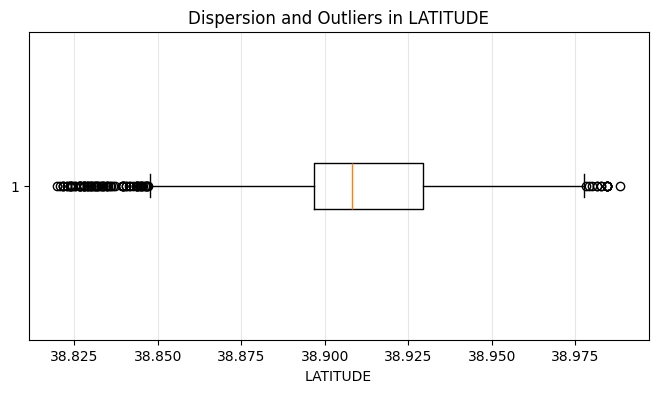

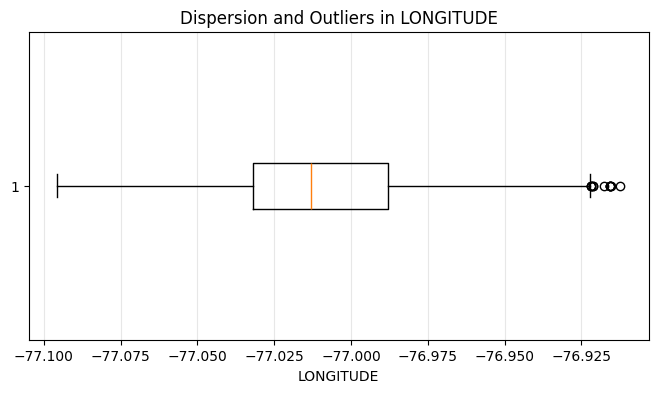

Numerical Features Used:
['LATITUDE', 'LONGITUDE']

Point A:
[ 38.90684583 -77.02498561]

Point B:
[ 38.87010864 -76.97900926]

Euclidean Distance:
0.058851041217967644


In [35]:
import numpy as np
import matplotlib.pyplot as plt

#1. Measures of Central Tendency
df['START_DATE'] = pd.to_datetime(df['START_DATE'], errors='coerce')
df['END_DATE'] = pd.to_datetime(df['END_DATE'], errors='coerce')

df['DURATION_MINUTES'] = (
    (df['END_DATE'] - df['START_DATE'])
    .dt.total_seconds() / 60
)

duration = df['DURATION_MINUTES'].dropna()
duration = duration[duration > 0]

print("Valid duration observations:", len(duration))
display(duration.describe())

arithmetic_mean = duration.mean()

print("Arithmetic Mean (Ungrouped Data):",
      round(arithmetic_mean, 2), "minutes")

bins = [0, 30, 60, 120, 240, np.inf]
labels = [
    '0-30 min',
    '30-60 min',
    '60-120 min',
    '120-240 min',
    '240+ min'
]

grouped_duration = pd.cut(
    duration,
    bins=bins,
    labels=labels,
    right=False
)

frequency_table = grouped_duration.value_counts().sort_index()

midpoints = [15, 45, 90, 180, 300]

grouped_mean = (
    frequency_table.values * np.array(midpoints)
).sum() / frequency_table.sum()

grouped_mean_table = pd.DataFrame({
    'Duration Group': frequency_table.index,
    'Frequency': frequency_table.values,
    'Midpoint': midpoints
})

display(grouped_mean_table)

print(
    "Arithmetic Mean (Grouped Data):",
    round(grouped_mean, 2),
    "minutes"
)

median_ungrouped = duration.median()

print(
    "Median (Ungrouped Data):",
    round(median_ungrouped, 2),
    "minutes"
)

freq = frequency_table.values
cum_freq = np.cumsum(freq)

N = freq.sum()
N_2 = N / 2
median_class_index = np.where(cum_freq >= N_2)[0][0]

L = bins[median_class_index]
F = cum_freq[median_class_index - 1] if median_class_index > 0 else 0
f = freq[median_class_index]

# Class width
if median_class_index < len(bins) - 2:
    h = bins[median_class_index + 1] - bins[median_class_index]
else:
    h = 60  # approximate width for open-ended final class

grouped_median = L + ((N_2 - F) / f) * h

print(
    "Median (Grouped Data):",
    round(grouped_median, 2),
    "minutes"
)

#2.Measures of Dispersion:
dispersion_features = [
    "LATITUDE",
    "LONGITUDE"
]

print("Selected Attributes:")
print(dispersion_features)

results = {}

for column in dispersion_features:

    data = df[column].dropna().astype(float)

mean_value = data.mean()
data_range = data.max() - data.min()

# Variance
variance = data.var()
# Standard Deviation
standard_deviation = data.std()
# Root Mean Square Deviation
rmsd = np.sqrt(np.mean((data - mean_value) ** 2))
# Coefficient of Dispersion
coefficient_of_dispersion = (standard_deviation / abs(mean_value))

results[column] = {
        "Mean": mean_value,
        "Minimum": data.min(),
        "Maximum": data.max(),
        "Range": data_range,
        "Variance": variance,
        "Standard Deviation": standard_deviation,
        "RMSD": rmsd,
        "Coefficient of Dispersion":
            coefficient_of_dispersion
  }

dispersion_table = pd.DataFrame(results).T

print("\nMeasures of Dispersion:")
display(
    dispersion_table.round(6)
)

#3. Shape Measures & Outlier Analysis:
for column in dispersion_features:

    plt.figure(figsize=(8, 4))

    plt.boxplot(
        df[column].dropna(),
        vert=False
    )

    plt.xlabel(column)
    plt.title(f"Dispersion and Outliers in {column}")
    plt.grid(axis="x", alpha=0.3)

    plt.show()


#4. Distance & Proximity Calculations
from scipy.spatial.distance import (
    euclidean,
    cityblock,
    minkowski,
    mahalanobis,
    jaccard,
    hamming,
    cosine
)

numeric_features = [
    "LATITUDE",
    "LONGITUDE"
]

print("Numerical Features Used:")
print(numeric_features)
numeric_data = df[numeric_features].dropna().reset_index(drop=True)

# First two observations
point_A = numeric_data.iloc[0].values.astype(float)
point_B = numeric_data.iloc[1].values.astype(float)

print("\nPoint A:")
print(point_A)

print("\nPoint B:")
print(point_B)

euclidean_distance = euclidean(
    point_A,
    point_B
)

print("\nEuclidean Distance:")
print(euclidean_distance)






# Phase 3

Continuous Attributes Selected:
['LATITUDE', 'LONGITUDE']

FREQUENCY DISTRIBUTION: LATITUDE


,Lower Boundary,Upper Boundary,Midpoint,Frequency,Relative Frequency (%),Cumulative Frequency
0,38.8197,38.8366,38.8282,54,2.6214,54
1,38.8366,38.8535,38.8451,49,2.3786,103
2,38.8535,38.8704,38.8619,123,5.9709,226
3,38.8704,38.8873,38.8788,178,8.6408,404
4,38.8873,38.9041,38.8957,439,21.3107,843
5,38.9041,38.9210,38.9126,558,27.0874,1401
6,38.9210,38.9379,38.9294,334,16.2136,1735
7,38.9379,38.9548,38.9463,140,6.7961,1875
8,38.9548,38.9716,38.9632,148,7.1845,2023
9,38.9716,38.9885,38.9801,37,1.7961,2060



FREQUENCY DISTRIBUTION: LONGITUDE


,Lower Boundary,Upper Boundary,Midpoint,Frequency,Relative Frequency (%),Cumulative Frequency
0,-77.0958,-77.0774,-77.0866,30,1.4563,30
1,-77.0774,-77.0591,-77.0683,93,4.5146,123
2,-77.0591,-77.0407,-77.0499,166,8.0583,289
3,-77.0407,-77.0224,-77.0316,577,28.0097,866
4,-77.0224,-77.0040,-77.0132,321,15.5825,1187
5,-77.0040,-76.9857,-76.9949,396,19.2233,1583
6,-76.9857,-76.9673,-76.9765,277,13.4466,1860
7,-76.9673,-76.9490,-76.9582,88,4.2718,1948
8,-76.9490,-76.9306,-76.9398,79,3.8350,2027
9,-76.9306,-76.9123,-76.9215,33,1.6019,2060


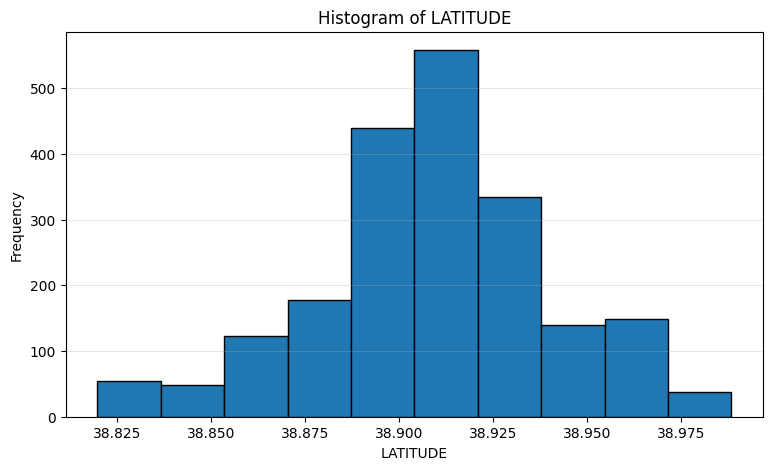

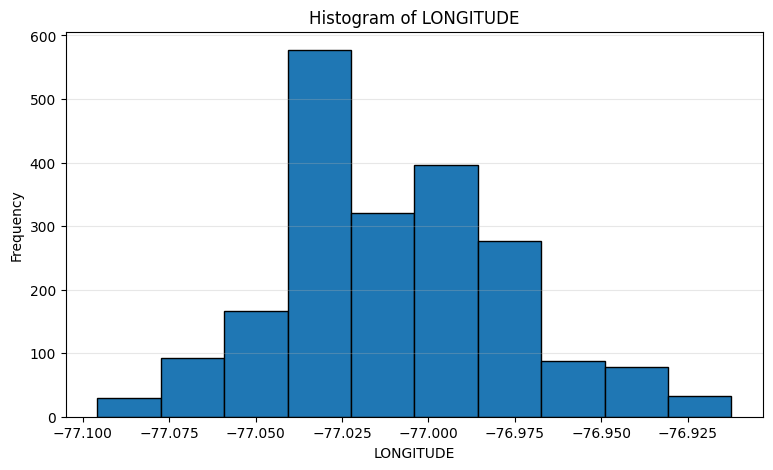

3.2.1 BOX PLOTS - SPREAD AND OUTLIER INSPECTION

Descriptive Statistics:


,X,Y,XBLOCK,YBLOCK,LATITUDE,LONGITUDE
count,2060.000000,2060.000000,2060.000000,2060.000000,2060.000000,2060.000000
mean,399186.233806,137955.658802,399186.233806,137955.658803,38.909457,-77.009389
std,2852.498858,3444.042301,2852.498858,3444.042301,0.031024,0.032889
min,391696.790000,127996.800000,391696.790000,127996.800000,38.819748,-77.095782
25%,397229.100000,136535.380000,397229.100000,136535.380000,38.896656,-77.031950
50%,398866.380000,137798.130000,398866.380000,137798.130000,38.908039,-77.013082
75%,401033.055000,140154.545000,401033.055000,140154.545000,38.929264,-76.988094
max,407609.013500,146731.260000,407609.013477,146731.260000,38.988511,-76.912290


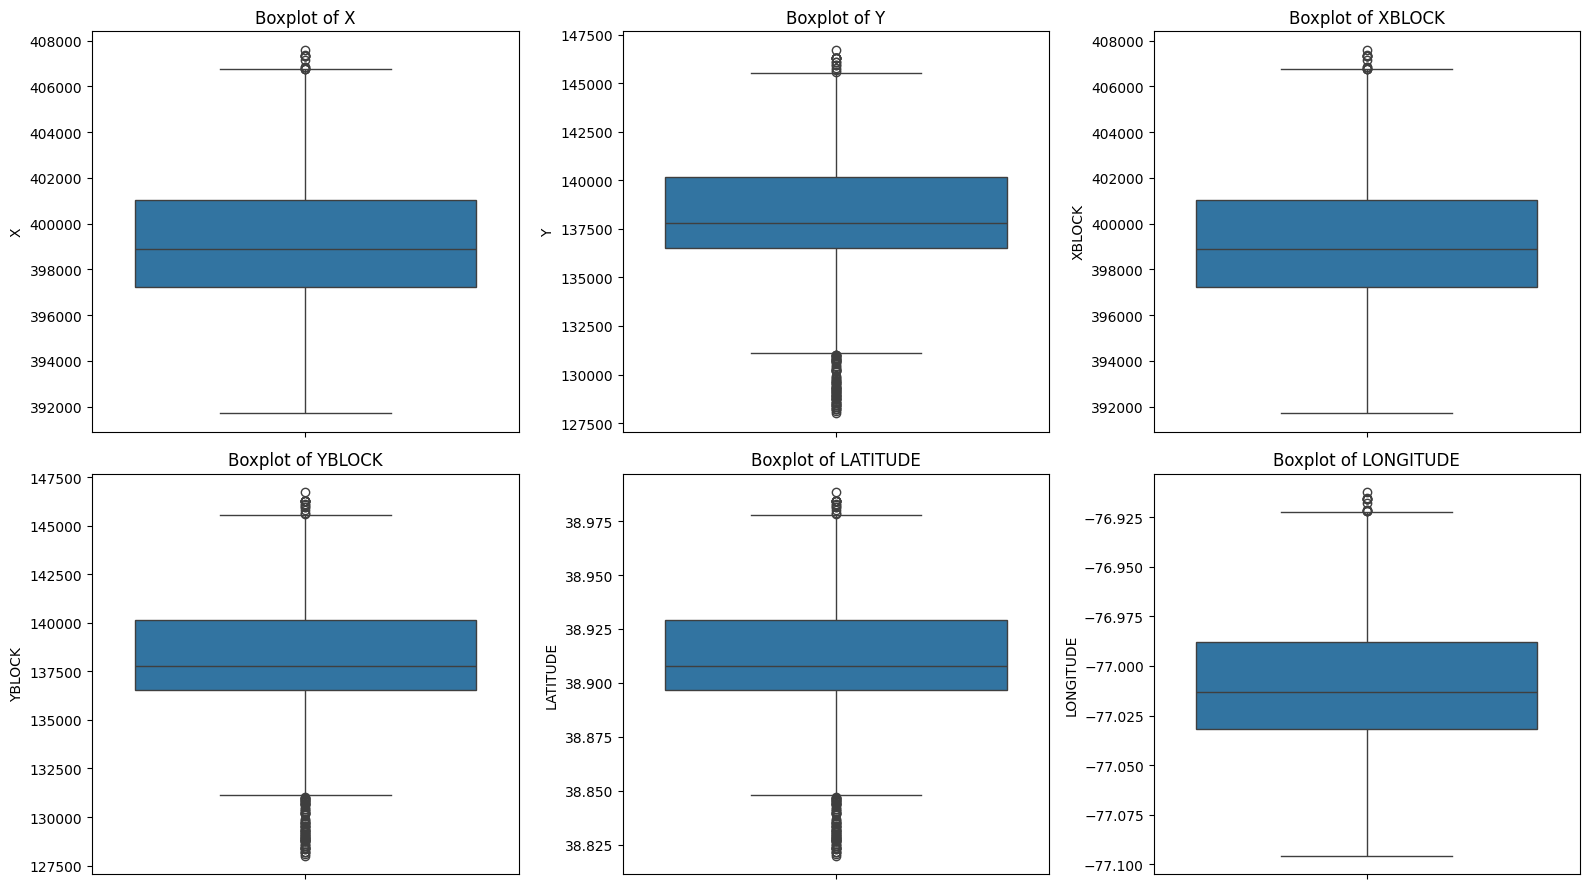


IQR-Based Outlier Summary:


,Variable,Q1,Q3,IQR,Lower Bound,Upper Bound,Potential Outliers
0,X,397229.1000,401033.0550,3803.9550,391523.1675,406738.9875,12
1,Y,136535.3800,140154.5450,3619.1650,131106.6325,145583.2925,97
2,XBLOCK,397229.1000,401033.0550,3803.9550,391523.1675,406738.9875,12
3,YBLOCK,136535.3800,140154.5450,3619.1650,131106.6325,145583.2925,97
4,LATITUDE,38.8967,38.9293,0.0326,38.8477,38.9782,97
5,LONGITUDE,-77.0320,-76.9881,0.0439,-77.0977,-76.9223,12


In [38]:
import seaborn as sns
#1.Frequency Distributions:
continuous_features = [
    "LATITUDE",
    "LONGITUDE"
]

print("Continuous Attributes Selected:")
print(continuous_features)

def frequency_distribution(data, column, bins=10):

    values = data[column].dropna().astype(float)

    # Create equal-width bins
    frequencies, bin_edges = np.histogram(
        values,
        bins=bins
    )

    # Class midpoints
    midpoints = (
        bin_edges[:-1] + bin_edges[1:]
    ) / 2

    # Cumulative frequency
    cumulative_frequency = np.cumsum(frequencies)

    # Relative frequency
    relative_frequency = (
        frequencies / len(values)
    ) * 100

    frequency_table = pd.DataFrame({
        "Lower Boundary": bin_edges[:-1],
        "Upper Boundary": bin_edges[1:],
        "Midpoint": midpoints,
        "Frequency": frequencies,
        "Relative Frequency (%)": relative_frequency,
        "Cumulative Frequency": cumulative_frequency
    })

    return frequency_table
frequency_tables = {}

for column in continuous_features:

    frequency_tables[column] = frequency_distribution(
        df,
        column,
        bins=10
    )

    print("\n" + "=" * 70)
    print(f"FREQUENCY DISTRIBUTION: {column}")
    print("=" * 70)

    display(
        frequency_tables[column].round(4)
    )


# ============================================================
# 3. HISTOGRAM
# ============================================================

for column in continuous_features:

    values = df[column].dropna()

    plt.figure(figsize=(9, 5))

    plt.hist(
        values,
        bins=10,
        edgecolor="black"
    )

    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.title(
        f"Histogram of {column}"
    )

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.show()

#2. Distribution & Outlier Inspection

from scipy import stats

print("3.2.1 BOX PLOTS - SPREAD AND OUTLIER INSPECTION")
print("=" * 60)

# Continuous numerical variables in the crime dataset
continuous_cols = [
    'X',
    'Y',
    'XBLOCK',
    'YBLOCK',
    'LATITUDE',
    'LONGITUDE'
]

# Keep only columns that exist in the dataset
continuous_cols = [
    col for col in continuous_cols
    if col in df.columns
]

# Display descriptive statistics
print("\nDescriptive Statistics:")
display(df[continuous_cols].describe())

# Create boxplots
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(16, 9)
)

axes = axes.flatten()

for ax, col in zip(axes, continuous_cols):

  sns.boxplot(
        y=df[col],
        ax=ax)

  ax.set_title(f'Boxplot of {col}')
  ax.set_ylabel(col)

# Hide unused plots
for ax in axes[len(continuous_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()


# Calculate IQR-based potential outliers
outlier_results = []

for col in continuous_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_results.append({
        'Variable': col,
        'Q1': round(Q1, 4),
        'Q3': round(Q3, 4),
        'IQR': round(IQR, 4),
        'Lower Bound': round(lower_bound, 4),
        'Upper Bound': round(upper_bound, 4),
        'Potential Outliers': len(outliers)
    })

outlier_summary = pd.DataFrame(outlier_results)

print("\nIQR-Based Outlier Summary:")
display(outlier_summary)




INFERENCES

PHASE 1

 The initial data analysis shows that the crime dataset contains 2,060 incidents described using spatial, temporal, categorical and administrative attributes. Attribute identification revealed that variables such as LATITUDE, LONGITUDE, X and Y are suitable for spatial analysis, while OFFENSE, METHOD and SHIFT are categorical variables suitable for frequency-based analysis. Data quality assessment showed that most attributes contain very little missing information, although BID and END_DATE have comparatively higher missingness. The completely empty OCTO_RECORD_ID attribute was removed, while categorical and limited missing values were handled appropriately without deleting incident records. Equal-width binning of latitude and longitude revealed that incidents are not uniformly distributed geographically: the Medium-High Latitude zone contains the largest number of incidents (969), while the Medium-Low Longitude zone contains the largest number of incidents (1,015). This indicates spatial concentration in specific coordinate ranges. These findings establish that location is an important dimension of the dataset and justify further analysis using spatial distributions, distance measures, outlier detection and geographic visualizations.

 PHASE 2:
Overall Inference: Phase 2 analysis reveals substantial variation in both the temporal duration and geographic distribution of crime incidents. Incident duration is strongly right-skewed, with a median of 63 minutes compared with a mean of 1,751.52 minutes and a maximum of 492,240 minutes. This large difference indicates that extreme-duration observations strongly influence the arithmetic mean, making the median a more representative measure of typical incident duration. The grouped mean of 119.70 minutes is considerably lower because the open-ended 240+ min category is represented by an approximate midpoint, causing extreme durations to be compressed. Spatial dispersion analysis shows that crime locations occupy a defined latitude-longitude range, while boxplots identify potential geographic outliers at the edges of the distribution. These spatial outliers should not automatically be removed because they may represent legitimate incidents occurring away from the main concentration. Finally, the Euclidean distance between the first two selected incidents was approximately 0.05885 coordinate units, demonstrating how spatial proximity can be quantified between incidents. Overall, the analysis indicates that both incident duration and geographic location contain meaningful variation, making them important variables for subsequent statistical and spatial analysis.

Phase3:
The frequency distribution and outlier analysis reveal a strong spatial concentration of recorded crime incidents. The latitude distribution reaches its highest frequency in the 38.9041–38.9210 interval, containing 558 incidents (27.09%), while the longitude distribution peaks at −77.0407 to −77.0224, containing 577 incidents (28.01%). The histograms confirm that observations are concentrated around the central coordinate ranges rather than uniformly distributed across the study area. The cumulative distributions further show that approximately 68% of incidents have latitude values up to 38.9210 and approximately 76.8% have longitude values up to −76.9857. IQR-based analysis identified 12 potential outliers in X/XBLOCK and longitude, and 97 potential outliers in Y/YBLOCK and latitude. The matching outlier patterns occur because these variables represent corresponding spatial dimensions in different coordinate systems. These observations should not automatically be treated as erroneous; they may represent legitimate incidents occurring toward the geographic boundaries of the dataset. Overall, the results indicate that crime incidents exhibit a clear spatial concentration with a smaller number of geographically extreme observations, supporting further hotspot, clustering and spatial proximity analysis.

